# Exploratory Data Analysis - Visualization

Key questions:
- How do `FlightNumber` and `PayloadMass` relate to the launch site?
- Which orbit types achieve the highest landing success rate?
- How does the success rate evolve year over year?

In [1]:
import pandas as pd, numpy as np
import matplotlib.pyplot as plt

np.random.seed(7)
df = pd.read_csv("data/spacex_launch_data.csv")
df["Year"] = pd.to_datetime(df["Date"]).dt.year
OK, BAD = "#2E7D32", "#C62828"
print(df.shape)
df.head()

(90, 10)

   FlightNumber        Date BoosterVersion  PayloadMass Orbit   LaunchSite    Customer  Class        LandingOutcome  Year
0             1  2010-06-04        F9 v1.0          500   LEO  CCAFS LC-40  Commercial      0            No attempt  2010
1             2  2010-12-08        F9 v1.0          544   LEO  CCAFS LC-40  Commercial      0  Failure (drone ship)  2010
2             3  2012-05-22        F9 v1.0          525   LEO  CCAFS LC-40  Commercial      0  Failure (drone ship)  2012
3             4  2012-10-08        F9 v1.0          500   LEO  CCAFS LC-40  Commercial      0  Failure (drone ship)  2012
4             5  2013-03-01        F9 v1.0          677   LEO  CCAFS LC-40  Commercial      0            No attempt  2013

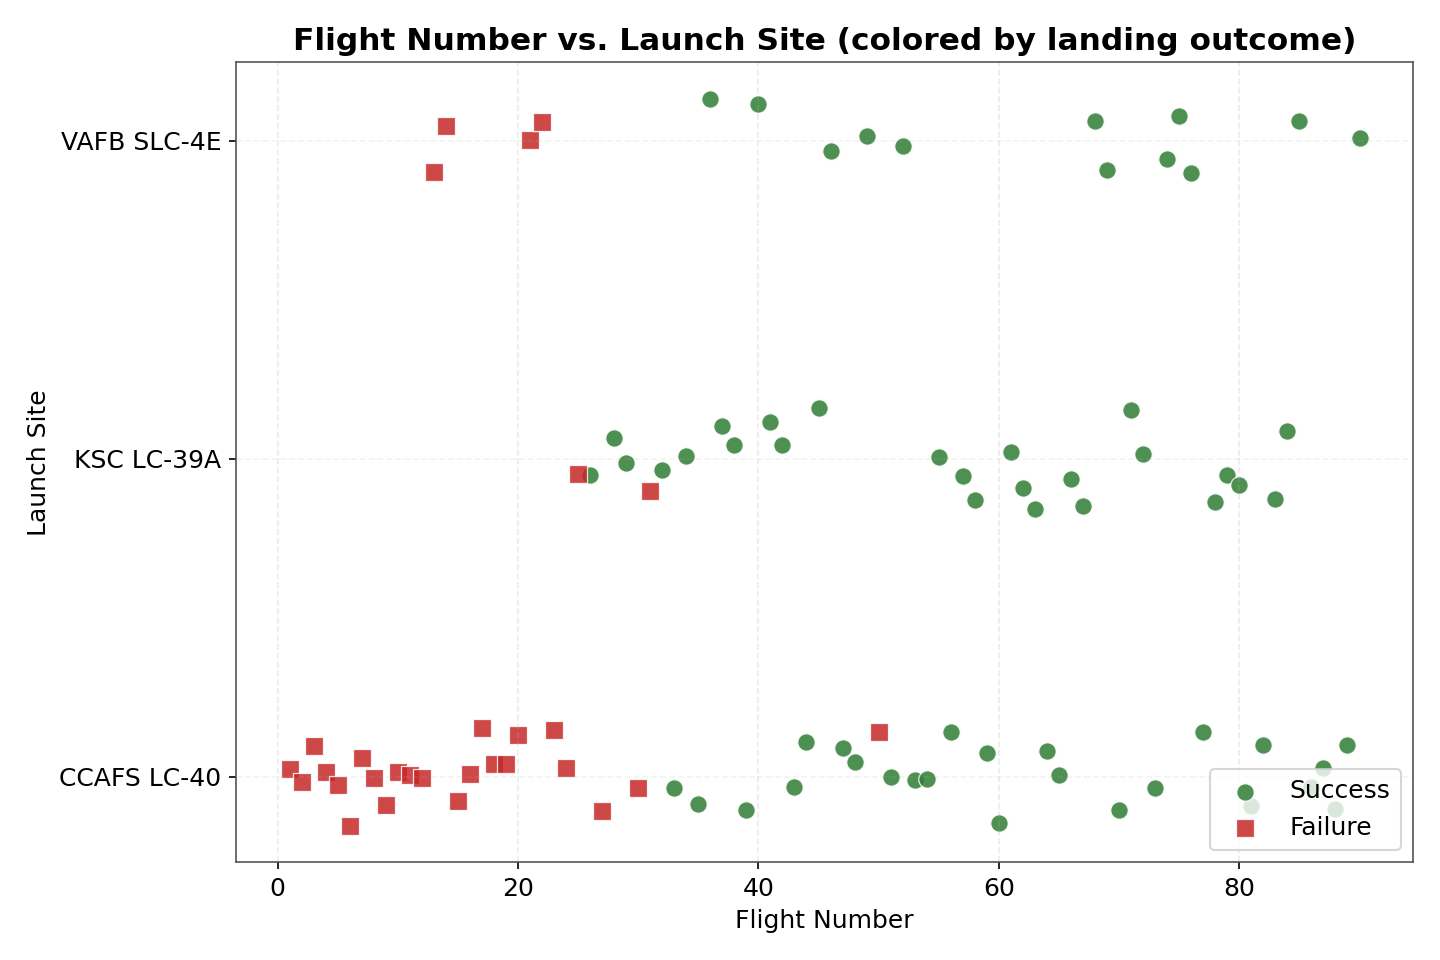

In [2]:
SITES = ["CCAFS LC-40", "KSC LC-39A", "VAFB SLC-4E"]
fig, ax = plt.subplots(figsize=(9.6, 6.4), dpi=110)
yticks = {c: i for i, c in enumerate(SITES)}
for c in yticks:
    sub = df[df["LaunchSite"] == c]
    ax.scatter(sub["FlightNumber"], [yticks[c]] * len(sub) + np.random.uniform(-0.16, 0.16, len(sub)),
               c=[OK if k == 1 else BAD for k in sub["Class"]], s=70, alpha=0.85, edgecolors="white")
ax.set_yticks(list(yticks.values())); ax.set_yticklabels(list(yticks.keys()))
ax.set_xlabel("Flight Number"); ax.set_ylabel("Launch Site")
ax.set_title("Flight Number vs. Launch Site (colored by landing outcome)", fontsize=15, weight="bold")
plt.show()

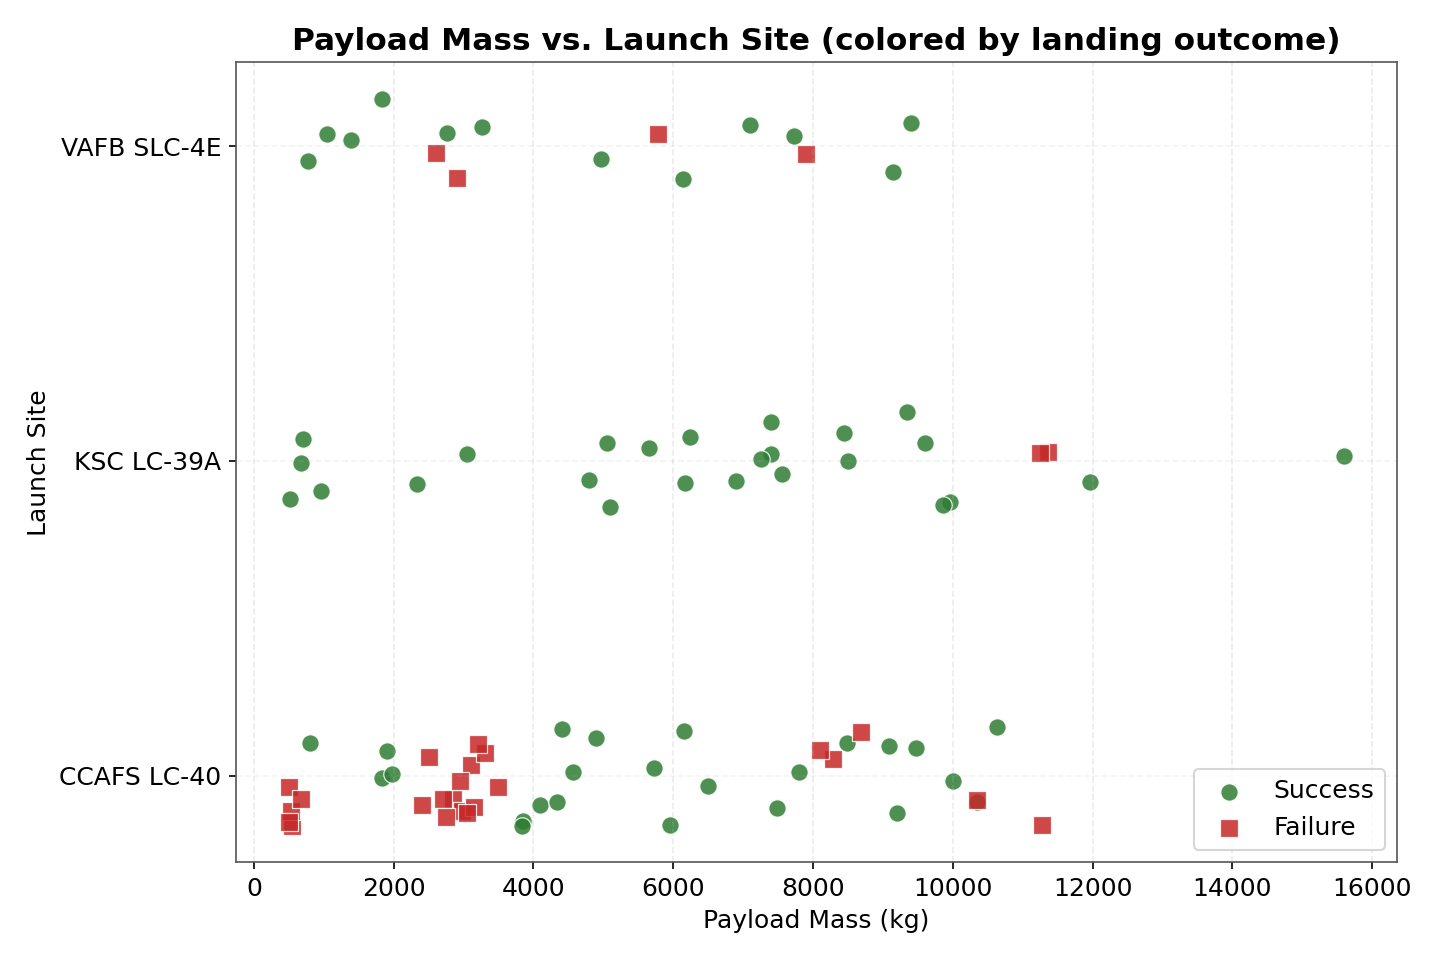

In [3]:
fig, ax = plt.subplots(figsize=(9.6, 6.4), dpi=110)
for c in yticks:
    sub = df[df["LaunchSite"] == c]
    ax.scatter(sub["PayloadMass"], [yticks[c]] * len(sub) + np.random.uniform(-0.16, 0.16, len(sub)),
               c=[OK if k == 1 else BAD for k in sub["Class"]], s=70, alpha=0.85, edgecolors="white")
ax.set_yticks(list(yticks.values())); ax.set_yticklabels(list(yticks.keys()))
ax.set_xlabel("Payload Mass (kg)"); ax.set_ylabel("Launch Site")
ax.set_title("Payload Mass vs. Launch Site (colored by landing outcome)", fontsize=15, weight="bold")
plt.show()

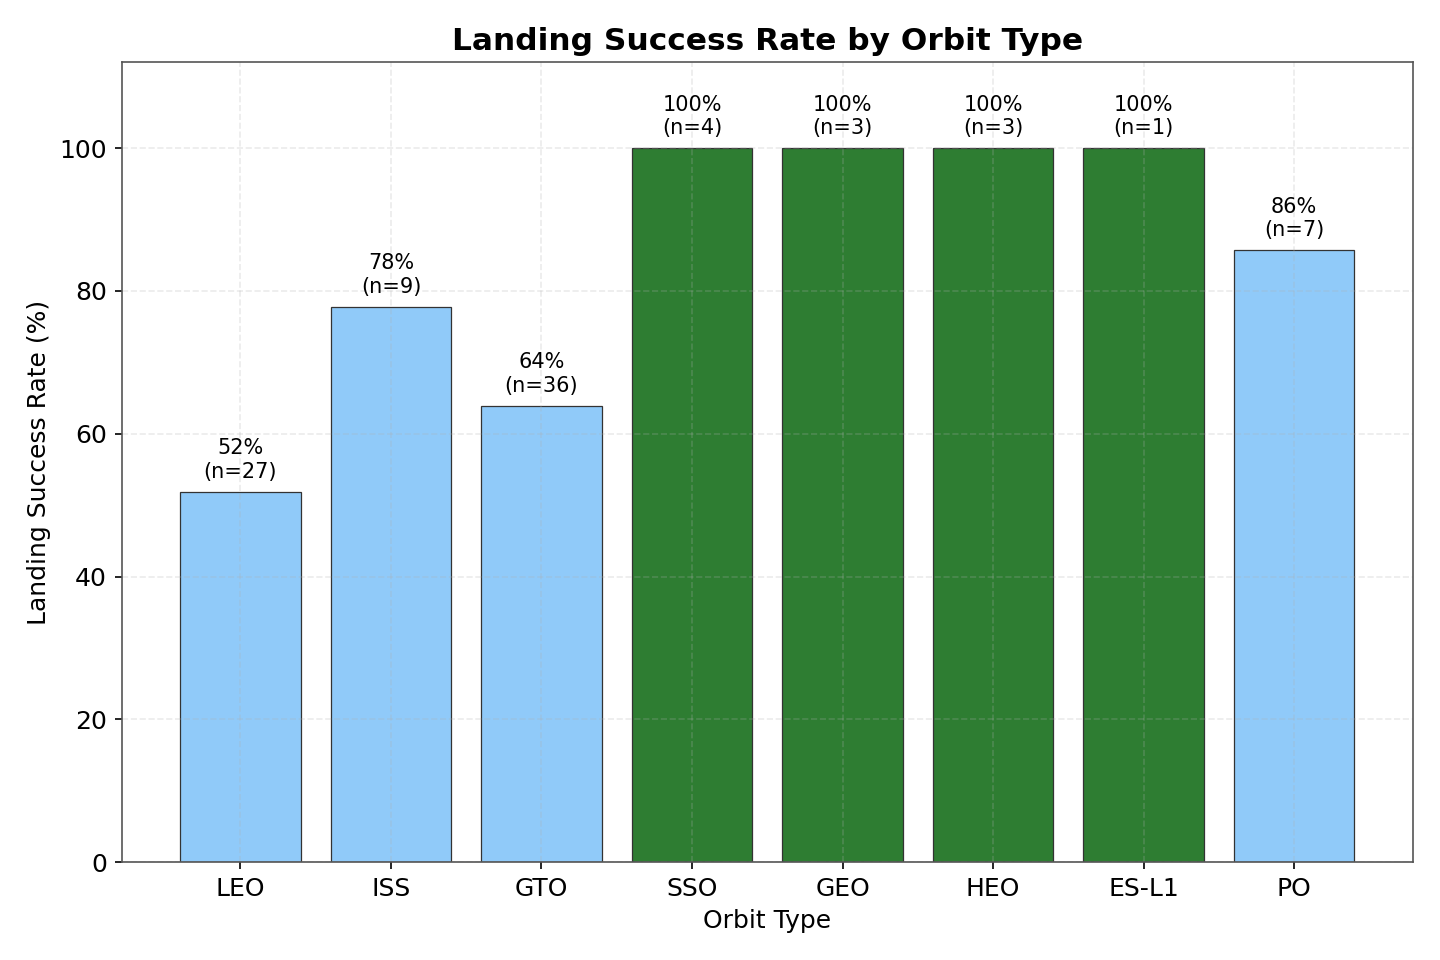

In [4]:
ORBITS = ["LEO", "ISS", "GTO", "SSO", "GEO", "HEO", "ES-L1", "PO"]
g = df.groupby("Orbit").Class.agg(["mean", "count"]).reindex(ORBITS)
fig, ax = plt.subplots(figsize=(9.6, 6.4), dpi=110)
ax.bar(ORBITS, g["mean"] * 100, color="#2E7D32", edgecolor="#333", linewidth=0.6)
for b, (m, n_) in zip(ax.patches, g.values):
    ax.text(b.get_x() + b.get_width() / 2, m * 100 + 2, f"{m*100:.0f}%\n(n={int(n_)})", ha="center", fontsize=10)
ax.set_ylim(0, 112); ax.set_ylabel("Landing Success Rate (%)")
ax.set_title("Landing Success Rate by Orbit Type", fontsize=15, weight="bold")
plt.show()

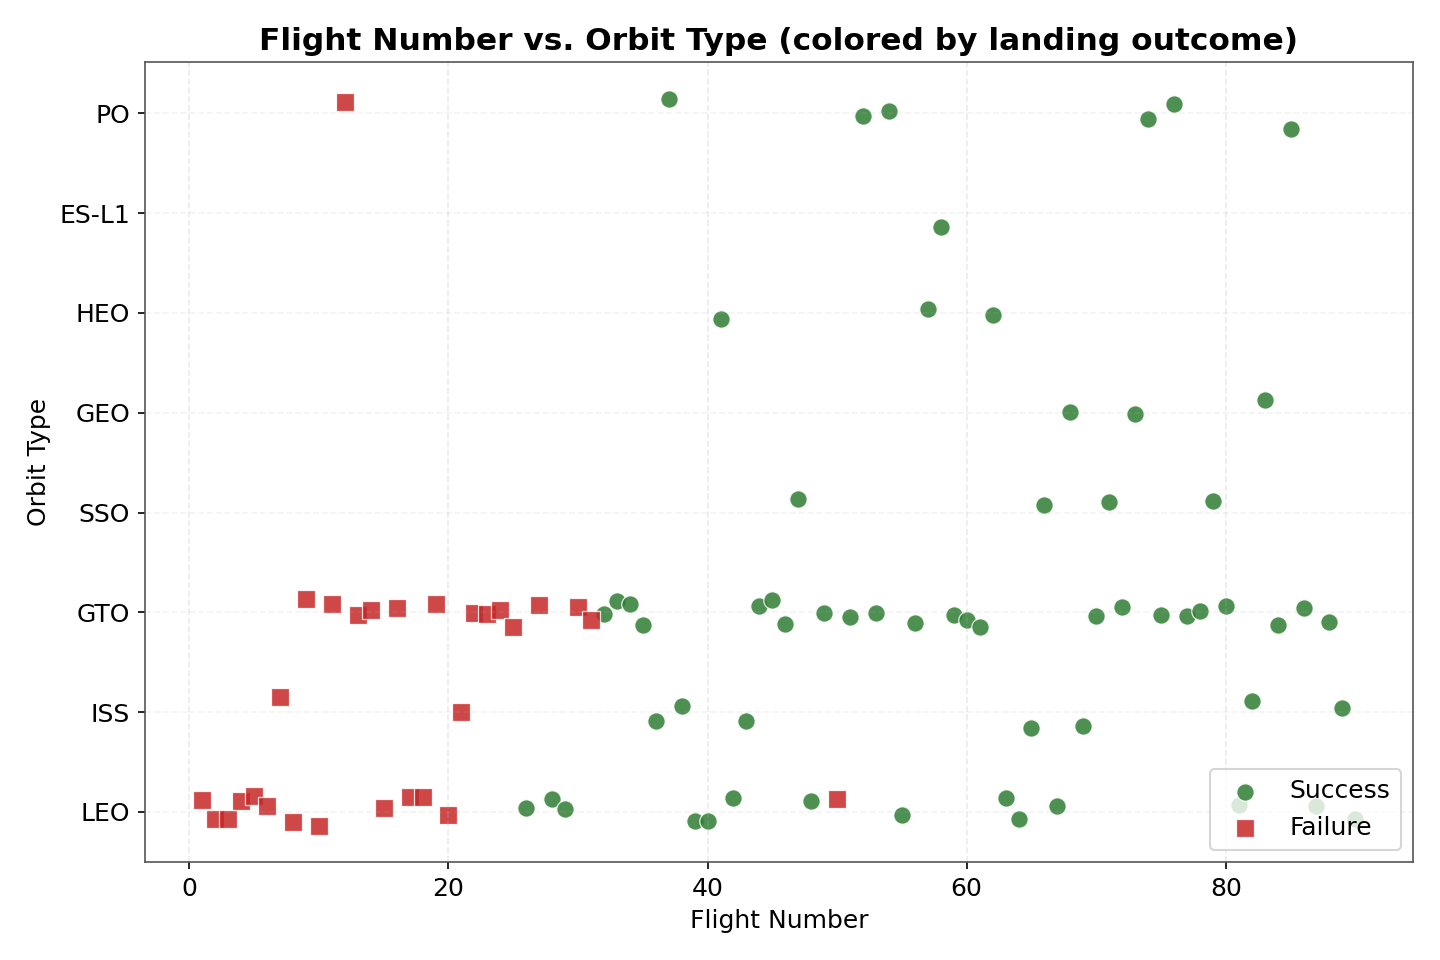

In [5]:
fig, ax = plt.subplots(figsize=(9.6, 6.4), dpi=110)
yticks = {c: i for i, c in enumerate(ORBITS)}
for c in yticks:
    sub = df[df["Orbit"] == c]
    ax.scatter(sub["FlightNumber"], [yticks[c]] * len(sub) + np.random.uniform(-0.16, 0.16, len(sub)),
               c=[OK if k == 1 else BAD for k in sub["Class"]], s=70, alpha=0.85, edgecolors="white")
ax.set_yticks(list(yticks.values())); ax.set_yticklabels(list(yticks.keys()))
ax.set_xlabel("Flight Number"); ax.set_ylabel("Orbit Type")
ax.set_title("Flight Number vs. Orbit Type (colored by landing outcome)", fontsize=15, weight="bold")
plt.show()

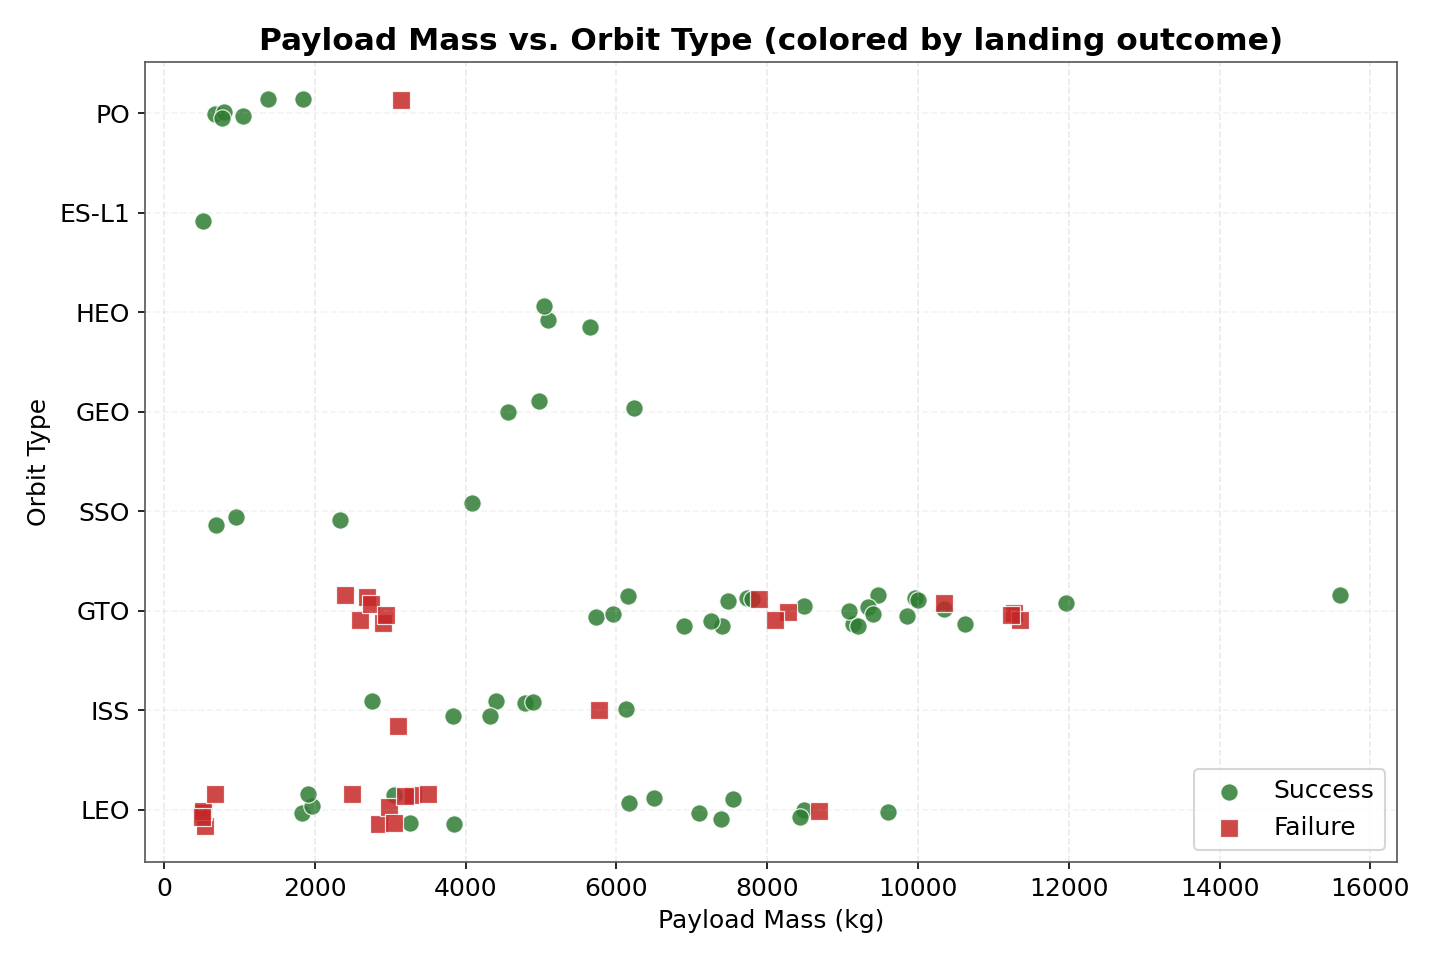

In [6]:
fig, ax = plt.subplots(figsize=(9.6, 6.4), dpi=110)
for c in yticks:
    sub = df[df["Orbit"] == c]
    ax.scatter(sub["PayloadMass"], [yticks[c]] * len(sub) + np.random.uniform(-0.16, 0.16, len(sub)),
               c=[OK if k == 1 else BAD for k in sub["Class"]], s=70, alpha=0.85, edgecolors="white")
ax.set_yticks(list(yticks.values())); ax.set_yticklabels(list(yticks.keys()))
ax.set_xlabel("Payload Mass (kg)"); ax.set_ylabel("Orbit Type")
ax.set_title("Payload Mass vs. Orbit Type (colored by landing outcome)", fontsize=15, weight="bold")
plt.show()

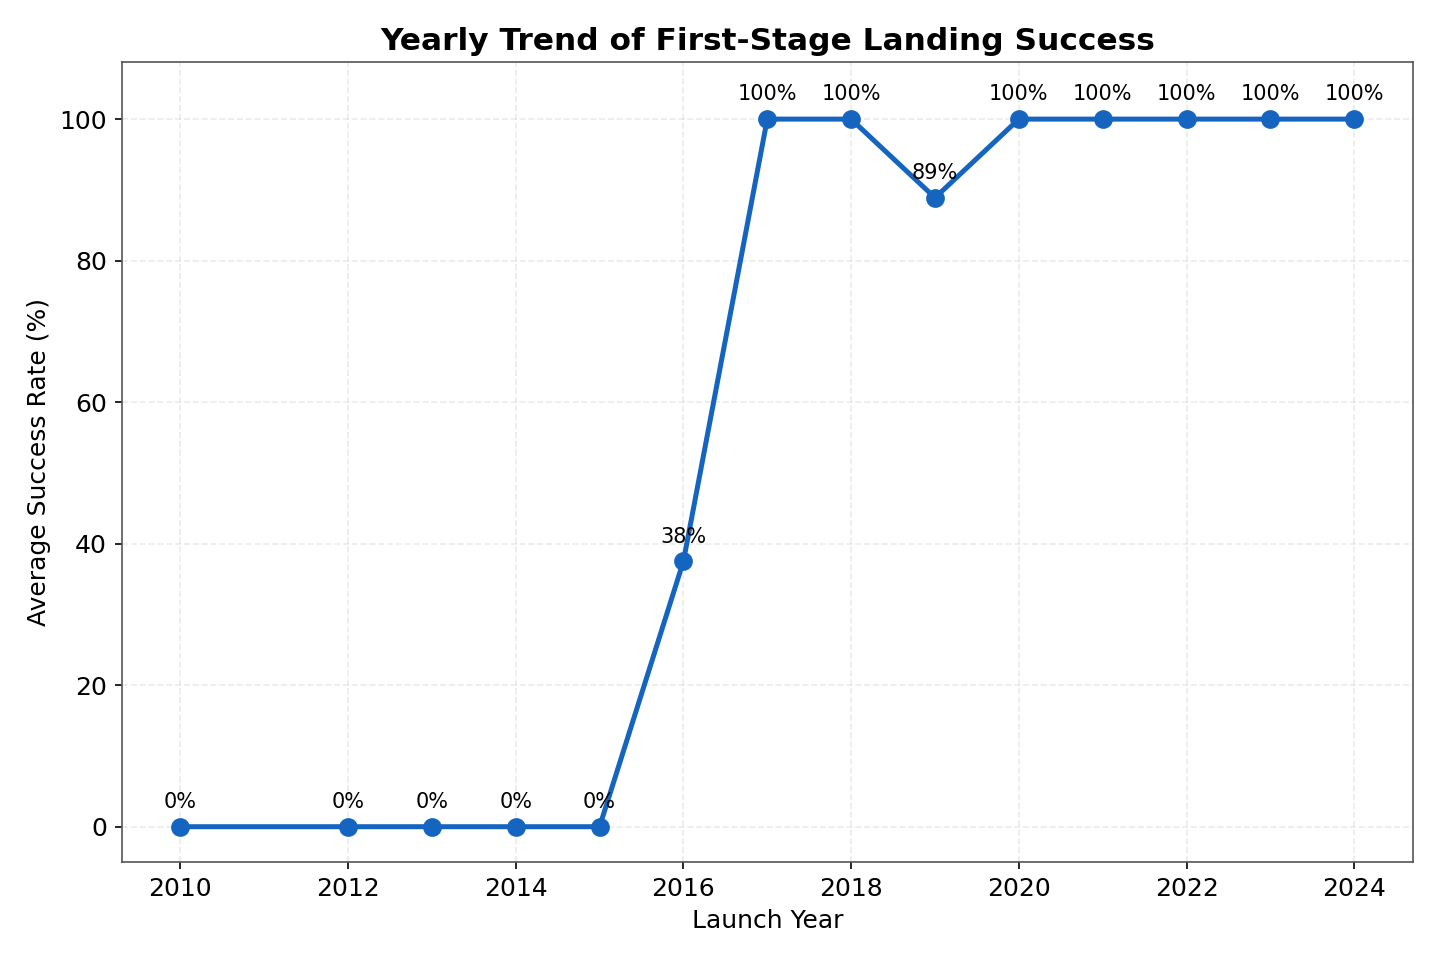

In [7]:
yr = df.groupby("Year").Class.mean() * 100
fig, ax = plt.subplots(figsize=(9.6, 6.4), dpi=110)
ax.plot(yr.index, yr.values, marker="o", lw=2.4, color="#1565C0", markersize=8)
ax.set_ylim(-5, 105); ax.set_xlabel("Year"); ax.set_ylabel("Landing Success Rate (%)")
ax.set_title("Yearly Trend of First-Stage Landing Success", fontsize=15, weight="bold")
plt.show()

## Findings

- Landing success improved from ~0% (through 2015) to ~100% (2017+)
- GTO missions remain the hardest; ES-L1, GEO, HEO and SSO reach ~100%
- Payload mass and orbit type are the dominant outcome factors